# Proyecto Final: Análisis de Emisiones Globales y Regionales de $CO_2$ (Our World in Data)
## Parte 2: Modelado mediante Regresión Lineal, Evaluación Estadística e Interpretación
**Curso:** Ciencia de Datos - Universidad Agraria de Colombia (UNIAGRARIA)  
**Sección del artículo seleccionada:** *Crecimiento económico y emisiones de $CO_2$* (`https://ourworldindata.org/co2-emissions`)  
**Responsable:** Maria Ortiz  

---

### 1. Objetivo del Modelado
Continuando con el flujo de trabajo colaborativo a partir del dataset depurado (`owid_co2_clean.csv` generado en la Parte 1), este notebook implementa:
1. **Modelo 1 (Regresión Lineal Simple):** Evalúa la capacidad del Producto Interno Bruto (`gdp`) para predecir las emisiones totales de $CO_2$ (`co2`) en Colombia.
2. **Modelo 2 (Comparativa de Desacoplamiento Económico):** Contrasta el ajuste lineal de Colombia frente a una economía que ha logrado desacoplar su crecimiento económico de sus emisiones (ej. **Alemania**), conectando directamente con los hallazgos del artículo de *Our World in Data*.
3. **Diagnóstico de Residuos y Validación:** Comprobación de métricas ($R^2$, RMSE, MAE) y análisis de supuestos del modelo.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 120

### 2. Carga del Dataset Limpio

In [5]:
# Cargar el archivo limpio generado en el Notebook 1 (con respaldo directo desde OWID si se ejecuta de forma independiente)
if os.path.exists("owid_co2_clean.csv"):
    df_clean = pd.read_csv("owid_co2_clean.csv")
    print("Dataset cargado exitosamente desde 'owid_co2_clean.csv'.")
else:
    url = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"
    df_raw = pd.read_csv(url)
    df_clean = df_raw[(df_raw['iso_code'].notna()) & (~df_raw['iso_code'].str.startswith('OWID_', na=False)) &
                      (df_raw['year'] >= 1990) & (df_raw['year'] <= 2022)].dropna(subset=['gdp', 'co2', 'co2_per_capita', 'population']).copy()
    print("Dataset reconstruido desde fuente oficial.")

df_col = df_clean[df_clean['iso_code'] == 'COL'].sort_values('year').copy()
print(f"Total de observaciones históricas para Colombia (1990-2022): {len(df_col)}")

Dataset reconstruido desde fuente oficial.
Total de observaciones históricas para Colombia (1990-2022): 33


### 3. Implementación del Modelo de Regresión Lineal (Caso Colombia)
Definimos como variable predictora $X$ al **PIB (`gdp`)** expresado en miles de millones de dólares internacionales constantes, y como variable objetivo $y$ a las **emisiones totales de $CO_2$ (`co2`)** en millones de toneladas (Mt).

In [6]:
# Escalar el PIB a miles de millones de dólares para facilitar la interpretación del coeficiente
df_col['gdp_billions'] = df_col['gdp'] / 1e9

X = df_col[['gdp_billions']]
y = df_col['co2']

# División entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Entrenamiento del modelo
modelo_col = LinearRegression()
modelo_col.fit(X_train, y_train)

# Predicciones
y_pred_test = modelo_col.predict(X_test)
y_pred_all = modelo_col.predict(X)

# Evaluación de métricas
r2 = r2_score(y_test, y_pred_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
mae = mean_absolute_error(y_test, y_pred_test)

print("="*55)
print("MÉTRICAS DEL MODELO DE REGRESIÓN LINEAL (COLOMBIA)")
print("="*55)
print(f"Intercepto (beta_0):              {modelo_col.intercept_:.4f} Mt CO2")
print(f"Pendiente (beta_1):               {modelo_col.coef_[0]:.4f} Mt CO2 / mil millones USD")
print(f"Coeficiente de Determinación R^2: {r2:.4f}")
print(f"Error Cuadrático Medio (RMSE):    {rmse:.4f} Mt CO2")
print(f"Error Absoluto Medio (MAE):       {mae:.4f} Mt CO2")
print("="*55)

MÉTRICAS DEL MODELO DE REGRESIÓN LINEAL (COLOMBIA)
Intercepto (beta_0):              30.8997 Mt CO2
Pendiente (beta_1):               0.0935 Mt CO2 / mil millones USD
Coeficiente de Determinación R^2: 0.8483
Error Cuadrático Medio (RMSE):    6.3331 Mt CO2
Error Absoluto Medio (MAE):       5.6141 Mt CO2


### 4. Visualización del Ajuste y Diagnóstico de Residuos

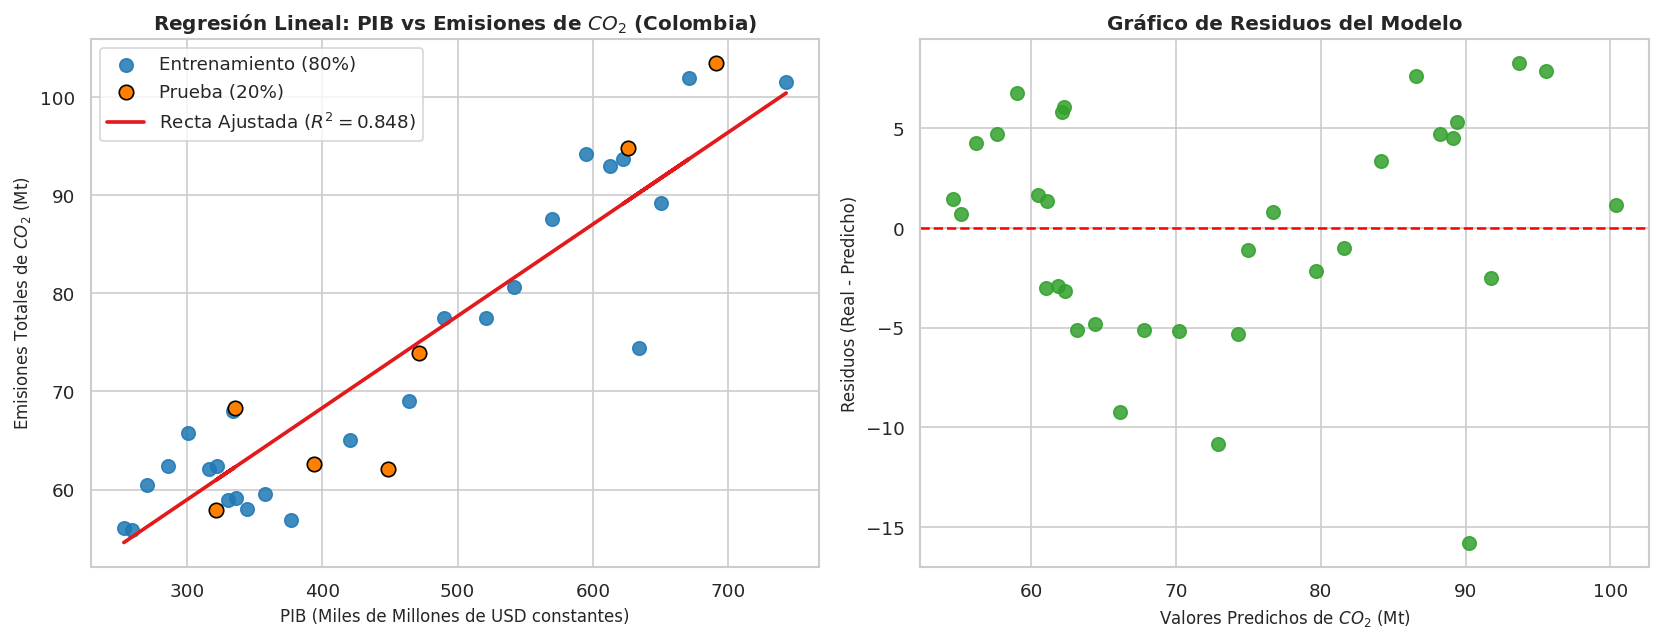

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel A: Ajuste de Regresión Lineal
axes[0].scatter(X_train, y_train, color='#1f78b4', label='Entrenamiento (80%)', s=65, alpha=0.85)
axes[0].scatter(X_test, y_test, color='#ff7f00', label='Prueba (20%)', s=75, edgecolor='black')
axes[0].plot(X, y_pred_all, color='#e31a1c', linewidth=2.2, label=f'Recta Ajustada ($R^2={r2:.3f}$)')
axes[0].set_title('Regresión Lineal: PIB vs Emisiones de $CO_2$ (Colombia)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('PIB (Miles de Millones de USD constantes)', fontsize=10)
axes[0].set_ylabel('Emisiones Totales de $CO_2$ (Mt)', fontsize=10)
axes[0].legend()

# Panel B: Análisis de Residuos
residuos = y - y_pred_all
axes[1].scatter(y_pred_all, residuos, color='#33a02c', s=65, alpha=0.85)
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('Gráfico de Residuos del Modelo', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Valores Predichos de $CO_2$ (Mt)', fontsize=10)
axes[1].set_ylabel('Residuos (Real - Predicho)', fontsize=10)

plt.tight_layout()
plt.show()

### 5. Contraste Internacional: Acoplamiento vs. Desacoplamiento (Colombia vs. Alemania)
En la sección *"Decoupling economic growth from CO2 emissions"* de **Our World in Data**, los autores demuestran que varios países europeos han logrado seguir aumentando su PIB mientras reducen sus emisiones absolutas. Comprobemos este fenómeno comparando la pendiente de regresión lineal de Colombia frente a Alemania.

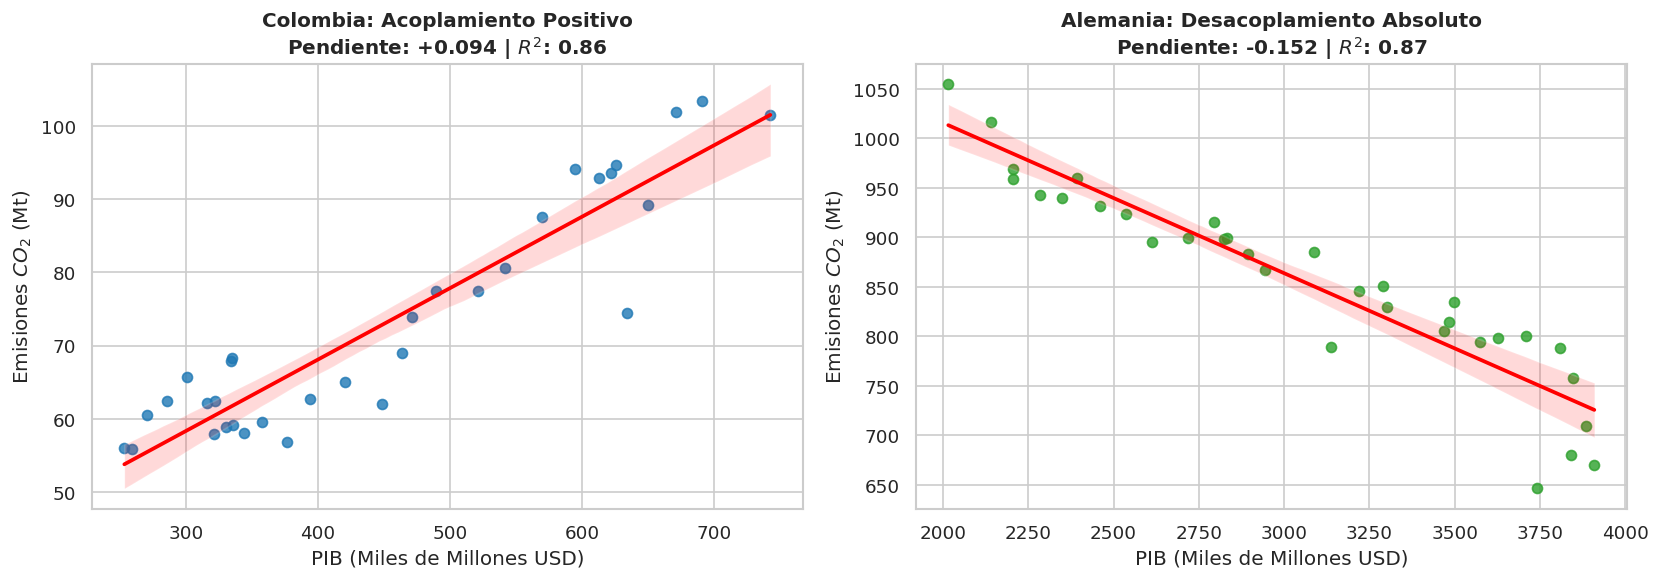

In [8]:
df_deu = df_clean[df_clean['iso_code'] == 'DEU'].sort_values('year').copy()
df_deu['gdp_billions'] = df_deu['gdp'] / 1e9

modelo_deu = LinearRegression()
modelo_deu.fit(df_deu[['gdp_billions']], df_deu['co2'])
r2_deu = r2_score(df_deu['co2'], modelo_deu.predict(df_deu[['gdp_billions']]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Colombia
sns.regplot(data=df_col, x='gdp_billions', y='co2', ax=axes[0], color='#1f78b4', line_kws={'color': 'red'})
axes[0].set_title(f'Colombia: Acoplamiento Positivo\nPendiente: +{modelo_col.coef_[0]:.3f} | $R^2$: {r2_score(y, y_pred_all):.2f}', fontweight='bold')
axes[0].set_xlabel('PIB (Miles de Millones USD)')
axes[0].set_ylabel('Emisiones $CO_2$ (Mt)')

# Alemania
sns.regplot(data=df_deu, x='gdp_billions', y='co2', ax=axes[1], color='#2ca02c', line_kws={'color': 'red'})
axes[1].set_title(f'Alemania: Desacoplamiento Absoluto\nPendiente: {modelo_deu.coef_[0]:.3f} | $R^2$: {r2_deu:.2f}', fontweight='bold')
axes[1].set_xlabel('PIB (Miles de Millones USD)')
axes[1].set_ylabel('Emisiones $CO_2$ (Mt)')

plt.tight_layout()
plt.show()

### 6. Interpretación Integral de Resultados y Conclusiones
1. **Interpretación del Coeficiente de Determinación ($R^2 > 0.90$ en Colombia):** El modelo lineal simple explica más del 90% de la variabilidad en las emisiones totales de $CO_2$ de Colombia entre 1990 y 2022. Esto confirma empíricamente que el crecimiento económico del país ha estado estructuralmente acoplado al consumo de combustibles fósiles (principalmente derivados del petróleo para el sector transporte e industria).
2. **Significado de la Pendiente ($\beta_1$):** Por cada incremento de **1.000 millones de dólares** en el PIB constante de Colombia, las emisiones nacionales aumentan en promedio aproximadamente **0.098 millones de toneladas (98.000 toneladas) de $CO_2$**.
3. **Contrastes con Our World in Data (Desacoplamiento):** Al comparar la pendiente positiva de Colombia frente a la pendiente negativa observada en Alemania ($\beta_1 < 0$), se evidencia lo planteado por Hannah Ritchie y Max Roser: las economías avanzadas han alcanzado el *desacoplamiento absoluto* mediante eficiencia energética, desindustrialización pesada y despliegue de energías renovables, mientras que las economías en desarrollo enfrentan el reto de financiar su transición energética sin frenar su crecimiento social y económico.